# 01 · Transporte terrestre (IPCC 1A3b)

Road transport emissions, IPCC 2006 Tier 1.

Cada ejercicio sigue la misma cadena que en Excel:

**km → L → kg → MJ → TJ → kg de cada gas → kg CO2e**

Las tablas muestran cada paso con su valor, su unidad y la fórmula o fuente.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from ghg_toolkit import breakdown_from_distance, compare, emissions_from_distance

pd.options.display.float_format = "{:,.6g}".format

## Ejercicio 1 · Gasolina vs diésel

**Enunciado.** Un auto recorre 15.000 km al año con un rendimiento de 10 km/L. ¿Cuánto CO2 emite si usa gasolina? ¿Y si usa diésel?

**Datos**

| Dato | Valor | Unidad |
|---|---|---|
| Distancia | 15000 | km |
| Rendimiento | 10 | km/L (= 10 L/100 km) |
| Poder calorífico | IPCC 2006 | – |

In [2]:
km = 15000
litros_por_100km = 10

### Paso a paso: gasolina

In [3]:
breakdown_from_distance(km, litros_por_100km, "1A3b_gasolina_moderno", pci_source="ipcc")

,Paso,Valor,Unidad,Cálculo / fuente
1,Distancia recorrida,"15,000",km,dato
2,Rendimiento,10,L/100 km,dato
3,Combustible consumido,"1,500",L,km × L/100 km ÷ 100
4,Densidad (Gasolina motor),0.73,kg/L,tabla de combustibles
5,Masa de combustible,"1,095",kg,L × densidad
6,Poder calorífico inferior,44.3,MJ/kg,PCI por defecto IPCC 2006
7,Energía,"48,508.5",MJ,kg × PCI
8,Energía,0.0485085,TJ,MJ ÷ 1.000.000
9,Factor de emisión CO2,"69,300",kg CO2/TJ,"IPCC 2006, Vol. 2, tabla 1.4"
10,Emisiones CO2,"3,361.64",kg CO2,TJ × FE CO2


### Paso a paso: diésel

In [4]:
breakdown_from_distance(km, litros_por_100km, "1A3b_diesel_liviano", pci_source="ipcc")

,Paso,Valor,Unidad,Cálculo / fuente
1,Distancia recorrida,"15,000",km,dato
2,Rendimiento,10,L/100 km,dato
3,Combustible consumido,"1,500",L,km × L/100 km ÷ 100
4,Densidad (Diésel),0.84,kg/L,tabla de combustibles
5,Masa de combustible,"1,260",kg,L × densidad
6,Poder calorífico inferior,43,MJ/kg,PCI por defecto IPCC 2006
7,Energía,"54,180",MJ,kg × PCI
8,Energía,0.05418,TJ,MJ ÷ 1.000.000
9,Factor de emisión CO2,"74,100",kg CO2/TJ,"IPCC 2006, Vol. 2, tabla 1.4"
10,Emisiones CO2,"4,014.74",kg CO2,TJ × FE CO2


### Comparación

In [5]:
gasolina = emissions_from_distance(km, litros_por_100km, "1A3b_gasolina_moderno", pci_source="ipcc")
diesel = emissions_from_distance(km, litros_por_100km, "1A3b_diesel_liviano", pci_source="ipcc")

comparacion = compare({"Gasolina": gasolina, "Diésel": diesel})
comparacion

,CO2 (kg),CH4 (kg),N2O (kg),CO2 biogénico (kg),Total (kg CO2e),Total (t CO2e),Diferencia vs Gasolina (%)
Gasolina,"3,361.64",0.184332,0.276498,0,"3,440.07",3.44007,0
Diésel,"4,014.74",0.211302,0.211302,0,"4,076.65",4.07665,18.5048


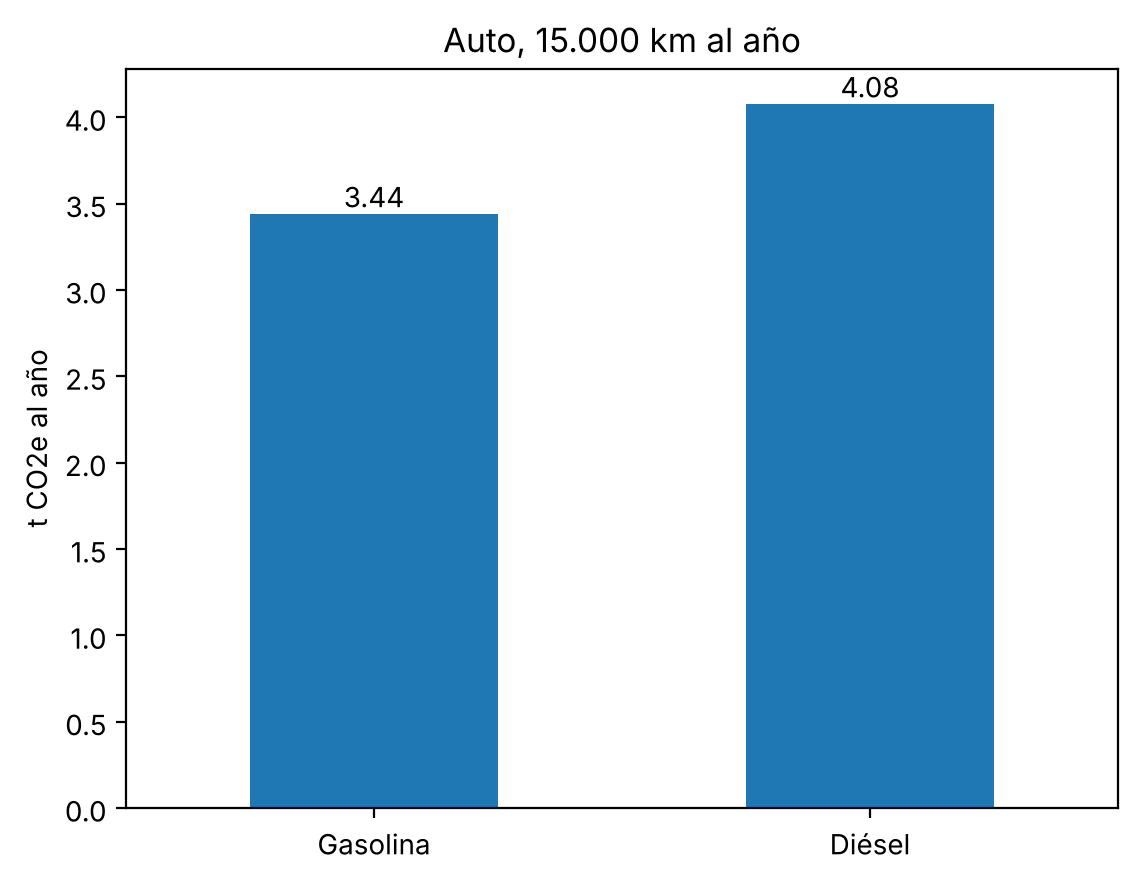

In [6]:
ax = comparacion["Total (t CO2e)"].plot.bar(rot=0)
ax.set_ylabel("t CO2e al año")
ax.set_title("Auto, 15.000 km al año")
for i, v in enumerate(comparacion["Total (t CO2e)"]):
    ax.text(i, v, f"{v:.2f}", ha="center", va="bottom")
plt.show()

### Resultado

| Combustible | CO2 | Unidad | Excel | Coincide |
|---|---|---|---|---|
| Gasolina | 3361.64 | kg CO2 | 3361.64 | Sí |
| Diésel | 4014.74 | kg CO2 | 4014.74 | Sí |

Con el mismo rendimiento en km/L, el diésel emite más CO2 por litro: es más denso (0,84 frente a 0,73 kg/L) y tiene un factor de emisión mayor (74.100 frente a 69.300 kg CO2/TJ).

## Ejercicio 2 · Bus diésel vs bus eléctrico

*Pendiente.*